<a href="https://colab.research.google.com/github/narzusid/First-Assignment/blob/main/Emotion_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q kaggle


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving kaggle (1).json to kaggle (1).json


In [ ]:
import os
print(os.listdir())

['.config', 'kaggle (1).json', 'sample_data']


In [ ]:
import os
import shutil

# Rename 'kaggle (1).json' to 'kaggle.json' if it hasn't been renamed yet
if os.path.exists("kaggle (1).json"):
    shutil.move("kaggle (1).json", "kaggle.json")

os.makedirs("/root/.kaggle", exist_ok=True)
shutil.copy("kaggle.json", "/root/.kaggle/kaggle.json")
os.chmod("/root/.kaggle/kaggle.json", 0o600)

print("Kaggle connected successfully!")

Kaggle connected successfully!


In [22]:
import os

# 1. Check if kaggle.json is uploaded, if not upload it
if not os.path.exists('/root/.kaggle/kaggle.json'):
    print("Please upload your kaggle.json file:")
    from google.colab import files
    files.upload()

    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json

# 2. Download FER-2013 dataset directly from Kaggle
print("Downloading FER-2013 dataset...")
!kaggle datasets download -d msambare/fer2013

# 3. Unzip the dataset
print("Extracting dataset...")
!unzip -q fer2013.zip -d emotion_data

print("Dataset connected and ready to use!")

Dataset URL: https://www.kaggle.com/datasets/msambare/fer2013
License(s): DbCL-1.0
100% 60.3M/60.3M [00:00<00:00, 119MB/s]

Extracting dataset...
Dataset connected and ready to use!


In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

# 1. Image Data Generators for FER-2013 Training and Validation
train_dir = 'emotion_data/train'
test_dir = 'emotion_data/test'

train_datagen = ImageDataGenerator(rescale=1./255, shear_range=0.2, zoom_range=0.2, horizontal_flip=True)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(48, 48),
    batch_size=64,
    color_mode='grayscale',
    class_mode='categorical'
)

validation_generator = test_datagen.flow_from_directory(
    test_dir,
    target_size=(48, 48),
    batch_size=64,
    color_mode='grayscale',
    class_mode='categorical'
)

# 2. Build CNN Model Architecture for Emotion Recognition
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(48, 48, 1)),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),
    Dropout(0.25),

    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(7, activation='softmax') # 7 emotion classes: Angry, Disgust, Fear, Happy, Neutral, Sad, Surprise
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 3. Train the Model
print("Training Emotion Detection Model...")
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)
print("Training Completed Successfully!")

Found 28709 images belonging to 7 classes.
Found 7178 images belonging to 7 classes.
Training Emotion Detection Model...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 157s 345ms/step - accuracy: 0.2687 - loss: 1.7743 - val_accuracy: 0.3488 - val_loss: 1.6459
Epoch 2/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 151s 337ms/step - accuracy: 0.3597 - loss: 1.6280 - val_accuracy: 0.4439 - val_loss: 1.4626
Epoch 3/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 151s 336ms/step - accuracy: 0.4174 - loss: 1.5080 - val_accuracy: 0.4689 - val_loss: 1.3830
Epoch 4/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 151s 336ms/step - accuracy: 0.4412 - loss: 1.4478 - val_accuracy: 0.4948 - val_loss: 1.3194
Epoch 5/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 149s 333ms/step - accuracy: 0.4639 - loss: 1.3951 - val_accuracy: 0.4958 - val_loss: 1.3072
Epoch 6/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 150s 333ms/step - accuracy: 0.4760 - loss: 1.3681 - val_accuracy: 0.5198 - val_loss: 1.2481
Epoch 7/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 151s 337ms/step - accuracy: 0.4852 - loss: 1.3462 - val_accuracy: 0.5266 - val_loss: 1.2259
Epoch 8/10
449/449 ━━━━━━━━━━━━━━━━━━━━ 153s 340ms/step - accuracy: 0.4980 -

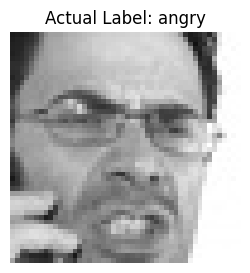

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
Dataset Actual Emotion: **ANGRY**
AI Model Prediction   : **ANGRY** (Confidence: 63.53%)


In [35]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt
import random
import os

# FER-2013 test directory
test_dir = 'emotion_data/test'
emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']

# Pick a random emotion folder and a random image from it
random_emotion = random.choice(os.path.exists(test_dir) and os.listdir(test_dir))
emotion_path = os.path.join(test_dir, random_emotion)
random_img_name = random.choice(os.listdir(emotion_path))
img_path = os.path.join(emotion_path, random_img_name)

# Load and display the test image
img_show = image.load_img(img_path)
plt.figure(figsize=(3, 3))
plt.imshow(img_show)
plt.axis('off')
plt.title(f"Actual Label: {random_emotion}")
plt.show()

# Process and Predict
img = image.load_img(img_path, target_size=(48, 48), color_mode='grayscale')
x = image.img_to_array(img)
x = np.expand_dims(x, axis=0)
x = x / 255.0

preds = model.predict(x)
predicted_emotion = emotion_labels[np.argmax(preds)]
confidence = np.max(preds) * 100

print(f"Dataset Actual Emotion: **{random_emotion.upper()}**")
print(f"AI Model Prediction   : **{predicted_emotion.upper()}** (Confidence: {confidence:.2f}%)")

In [36]:
import os
import shutil
from google.colab import files

# List of the 7 emotion categories
emotions = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

# Create a directory to store selected images
os.makedirs('selected_emotions', exist_ok=True)

# Copy one sample image for each emotion from the dataset
for emotion in emotions:
    train_path = os.path.join('emotion_data/train', emotion)
    if os.path.exists(train_path):
        # Select the first image from the folder
        img_name = os.listdir(train_path)[0]
        src_path = os.path.join(train_path, img_name)

        # Copy to the new folder and rename it with the emotion label
        dst_path = os.path.join('selected_emotions', f"{emotion}.jpg")
        shutil.copy(src_path, dst_path)

# Compress all images into a zip archive
shutil.make_archive('all_emotions_images', 'zip', 'selected_emotions')

print("All emotion images have been successfully zipped. Downloading now...")

# Download the zip file directly to your laptop
files.download('all_emotions_images.zip')

All emotion images have been successfully zipped. Downloading now...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

print("Please upload a face expression image to test:")
uploaded = files.upload()

emotion_labels = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']

for fn in uploaded.keys():
    # Load and display the uploaded image
    img_show = image.load_img(fn)
    plt.figure(figsize=(4, 4))
    plt.imshow(img_show)
    plt.axis('off')
    plt.title("Uploaded Test Image")
    plt.show()

    # Process the image for the trained model
    img = image.load_img(fn, target_size=(48, 48), color_mode='grayscale')
    x = image.img_to_array(img)
    x = np.expand_dims(x, axis=0)
    x = x / 255.0

    # Predict emotion
    preds = model.predict(x)
    predicted_emotion = emotion_labels[np.argmax(preds)]
    confidence = np.max(preds) * 100

    print(f"File Name: {fn}")
    print(f"AI Detected Emotion -> **{predicted_emotion.upper()}** (Confidence: {confidence:.2f}%)")

Please upload a face expression image to test:
